# Silicon in a finite electric field

What does a crystal do in a static, uniform electric field? The electrons shift against the
field, and the crystal gets a polarization $\mathbf P$. The ratio is the dielectric
susceptibility, and $\varepsilon_\infty = 1 + 4\pi\,\partial P/\partial E$.

In a periodic crystal we cannot add $-e\mathbf E\cdot\mathbf r$ to the Hamiltonian, because
$\mathbf r$ is not periodic. So we minimise the electric enthalpy instead (Souza, Iniguez and
Vanderbilt, [arXiv:cond-mat/0205633](https://arxiv.org/abs/cond-mat/0205633)):

$$F[\psi] = E_{\rm KS}[\psi] - \Omega\,\mathbf E\cdot\mathbf P[\psi].$$

Here $\mathbf P$ is the Berry phase of the occupied bands along strings of k-points
(King-Smith and Vanderbilt). Its derivative with respect to the wavefunctions is an operator
that couples each k-point to its two neighbours on the string. This is `lelfield` in
`pw.x`, and we use the same input.

The cell is the 8-atom silicon cube of the Quantum ESPRESSO test suite, with 9 strings of 7
k-points along $z$. Against `pw.x` 7.5 the total energy agrees to 1e-8 Ry and the forces
to 1e-7 Ry/bohr.

In [1]:
import warnings
from pathlib import Path

from defuqumat import Calculator

CASES, PSEUDO = Path("../tests/data/qe"), Path("../tests/data/pseudo")
warnings.filterwarnings("ignore", message="tstress")   # the stress is not available with the field

crystal = Calculator.from_file(CASES / "si8-lelfield-zero.in", pseudo_dir=PSEUDO, announce=False)
ground = crystal.get_scf()
field = Calculator.from_file(CASES / "si8-lelfield.in", pseudo_dir=PSEUDO, announce=False)
scf = field.get_scf(starting_from=ground)
el, ion, jumps = scf.berry_dipoles
print("E = %.10f Ry   electronic dipole %.6f Ry a.u." % (scf.total_energy, el))

E = -63.0661033823 Ry   electronic dipole 0.929957 Ry a.u.


The field is switched on from the converged state without field. This is what `pw.x` does
in its test, and it matters: from random wavefunctions the occupied bands at two neighbouring
k-points are almost orthogonal, and the field operator is then very large.

## The same numbers in `pw.x`

`pw.x` prints the electronic and the ionic dipole of the cell, in Ry atomic units. The ionic
part is $\sqrt2\sum_a Z_a\tau_{a,z}$ and is the same in both codes by construction. The
electronic part is the physics.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from defuqumat.io import comparison_table, read_qe_output

qe = read_qe_output(CASES / "reference.out.si8-lelfield")
text = (CASES / "reference.out.si8-lelfield").read_text()
qe_el = float(text.rsplit("Electronic Dipole per cell (Ry a.u.)", 1)[1].split()[0])
force = field.get_forces().forces
rows = [("total energy [Ry]", scf.total_energy, qe.total_energy),
        ("electronic dipole [Ry a.u.]", el, qe_el),
        ("force on atom 1, z [Ry/bohr]", force[0, 2], qe.forces[0, 2])]
print(comparison_table(rows, fmt="{:.8f}", headers=("", "defuqumat", "pw.x", "difference")))

                                 defuqumat          pw.x  difference
total energy [Ry]             -63.06610338  -63.06610337     1.2e-08
electronic dipole [Ry a.u.]     0.92995686    0.92996548     8.6e-06
force on atom 1, z [Ry/bohr]   -0.01251766   -0.01251774     7.6e-08


The electronic dipole of `pw.x` still moves by 1.6e-5 between its last two iterations, so
the difference above is inside its convergence.

## The dielectric constant from the polarization

We now run five fields, from $-0.002$ to $+0.002$ Ry a.u. (0.002 Ry a.u. is about
$7\times10^8$ V/m). The dipole in Ry atomic units is $\sqrt2$ times the dipole in $e\cdot$bohr,
and the field in Ry atomic units is $\sqrt2$ times the field in Hartree units. So the two
factors cancel, and $\chi = (\partial\,\mathrm{el\_pol}/\partial E)/\Omega$.

In [3]:
text = (CASES / "si8-lelfield.in").read_text()
fields = np.array([-0.002, -0.001, 0.0, 0.001, 0.002])
dipoles = []
for e in fields:
    run = Calculator.from_text(text.replace("efield=0.001", f"efield={e}"),
                               pseudo_dir=PSEUDO, announce=False)
    dipoles.append(run.get_scf(starting_from=ground).berry_dipoles[0])
dipoles = np.array(dipoles)
volume = float(field.system.cell.volume)
slope = (dipoles[3] - dipoles[1]) / 0.002          # the odd part, at E = 0
print("eps_inf = %.2f" % (1 + 4 * np.pi * slope / volume))

eps_inf = 12.08


The measured $\varepsilon_\infty$ of silicon is 11.7. Semilocal functionals give a value
above it, because their gap is too small. Here the mesh is 3x3x7 points in a cell of 8
atoms, so the number is also not converged in k. The residual of the linear fit in the figure is odd in the field. So it is the
third-order response, a term in $E^3$. Silicon has inversion symmetry, so there is no
second-order term. The atoms here sit at $\pm0.123$ instead of $\pm0.125$, which gives the
forces, but the cell keeps the inversion.

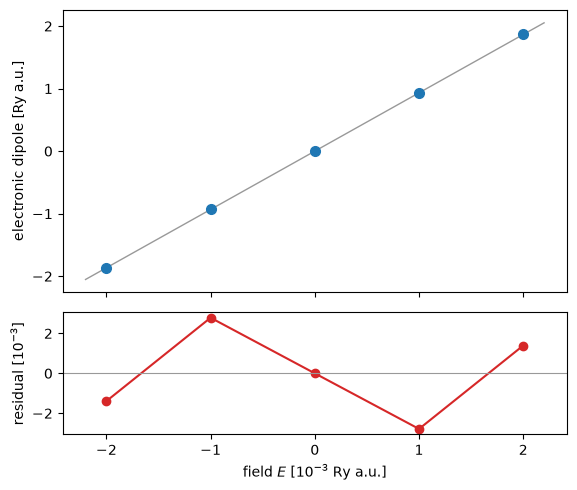

In [4]:
fit = np.polyfit(fields, dipoles, 1)
fig, (ax, res) = plt.subplots(2, 1, figsize=(6.0, 5.0), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.3]})
grid = np.linspace(-0.0022, 0.0022, 50)
ax.plot(grid * 1e3, np.polyval(fit, grid), color="0.6", lw=1)
ax.plot(fields * 1e3, dipoles, "o", color="tab:blue", ms=7)
ax.set_ylabel("electronic dipole [Ry a.u.]")
res.plot(fields * 1e3, (dipoles - np.polyval(fit, fields)) * 1e3, "o-", color="tab:red")
res.axhline(0, color="0.6", lw=0.8)
res.set_xlabel(r"field $E$ [$10^{-3}$ Ry a.u.]")
res.set_ylabel(r"residual [$10^{-3}$]")
fig.tight_layout()

## What to remember

- `lelfield` puts a finite uniform field into a periodic crystal through the Berry phase. The
  energy is the electric enthalpy, and the forces include the field.
- Switch the field on from a converged state without field, as `pw.x` does.
- The field must stay below the breakdown field of the k-mesh. Above it, electrons can
  tunnel from the valence to the conduction band between neighbouring k-points, and the
  enthalpy has no minimum.
- An ultrasoft or PAW dataset, two spin channels and the three-direction form
  (`efield_cart`) give an error, and so does the stress.

The checks against `pw.x`, and the check that the energy difference between two fields is
the integral of the dipole, are in `tests/regression/test_berryfield.py`.